In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình chung cho toàn bộ biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 6)

def load_sql_to_df(sql_filename):
    """Hàm tiện ích tự động đọc file SQL từ thư mục sql/ và trả về DataFrame"""
    conn = sqlite3.connect('../sql/steam_database.db')
    file_path = f'../sql/{sql_filename}'
    
    with open(file_path, 'r', encoding='utf-8') as f:
        query = f.read()

    query = query.replace('price_initial_USD', '"price_initial (USD)"')
    
    df = pd.read_sql(query, conn)
    conn.close()
    return df

print("Đã thiết lập xong module kết nối và đọc file SQL tự động!")

Đã thiết lập xong module kết nối và đọc file SQL tự động!


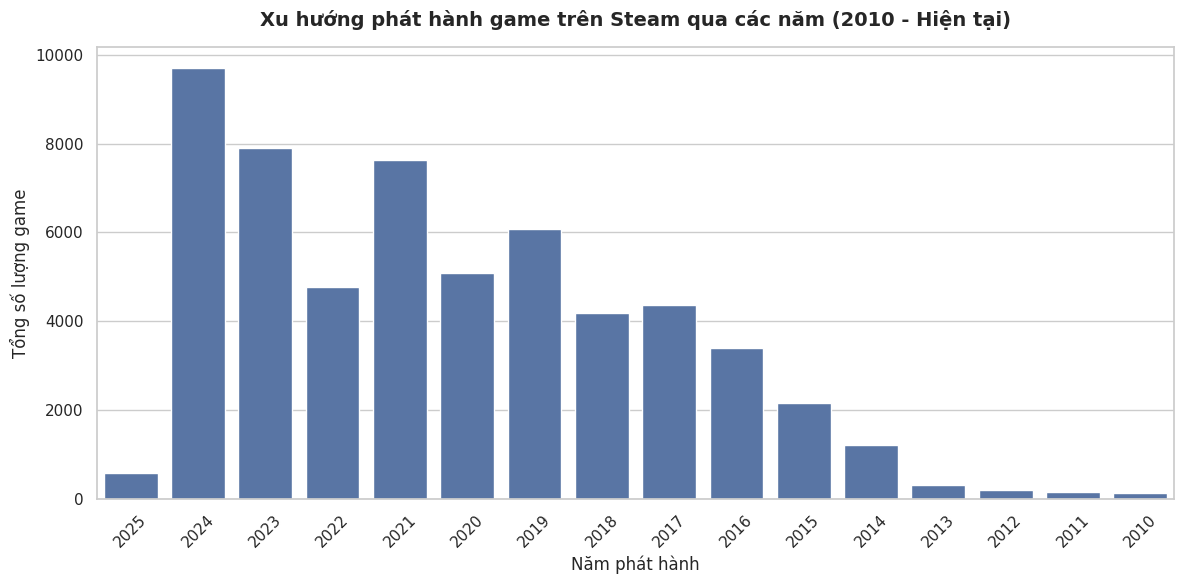

In [3]:
# Gọi hàm để lấy dữ liệu BQ1 từ file SQL
df_bq1 = load_sql_to_df('bq01_release_trend.sql')

# Lọc dữ liệu từ năm 2010 đến nay để biểu đồ tập trung và dễ nhìn hơn
df_bq1['release_year'] = df_bq1['release_year'].astype(str)
df_filtered = df_bq1[df_bq1['release_year'] >= '2010']

# Vẽ biểu đồ bằng Seaborn & Matplotlib
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_filtered, 
    x='release_year', 
    y='total_games', 
)

plt.title('Xu hướng phát hành game trên Steam qua các năm (2010 - Hiện tại)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Năm phát hành', fontsize=12)
plt.ylabel('Tổng số lượng game', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

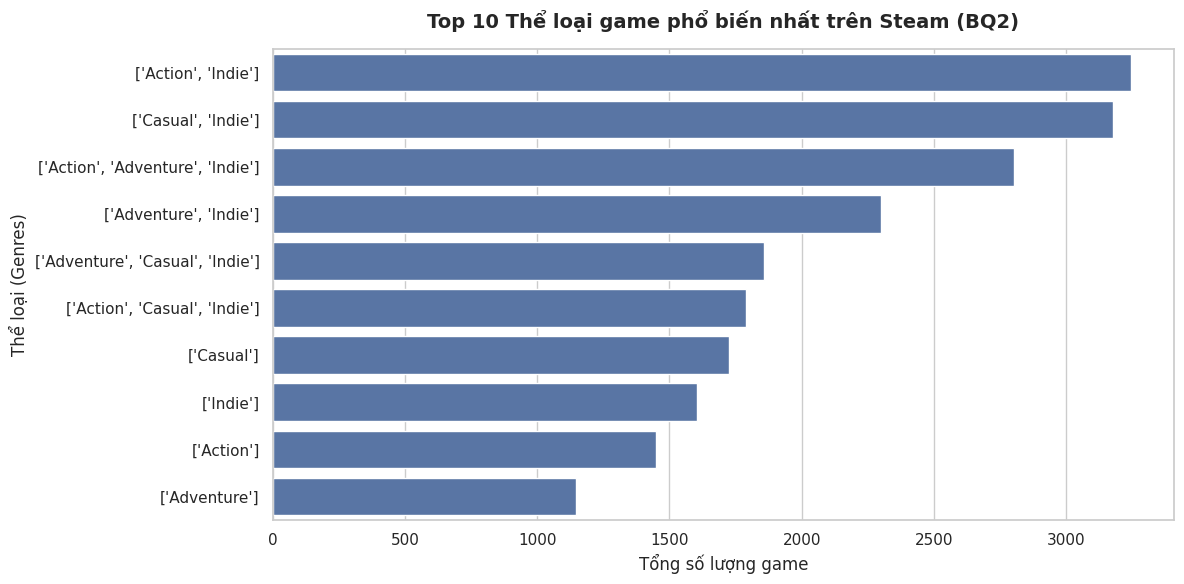

In [4]:
# Gọi hàm để lấy dữ liệu BQ2 từ file SQL
df_bq2 = load_sql_to_df('bq02_genre_analysis.sql')

# Lấy top 10 thể loại phổ biến nhất để biểu đồ gọn gàng, dễ đọc
df_top10_genres = df_bq2.head(10)

# Vẽ biểu đồ cột ngang (horizontal bar chart) cho dễ nhìn tên các thể loại
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_top10_genres, 
    x='total_games', 
    y='genres'
)

plt.title('Top 10 Thể loại game phổ biến nhất trên Steam (BQ2)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tổng số lượng game', fontsize=12)
plt.ylabel('Thể loại (Genres)', fontsize=12)

plt.tight_layout()
plt.show()

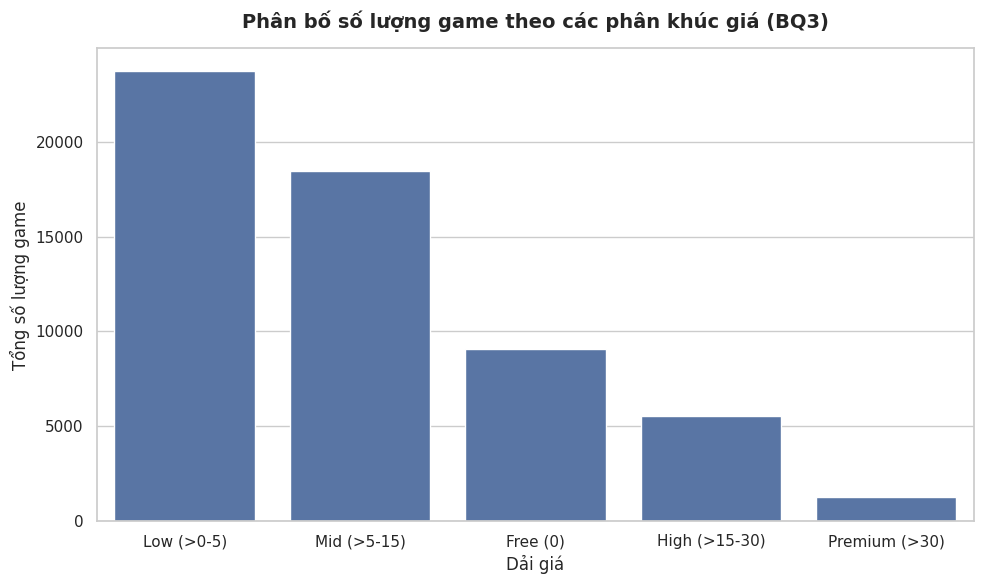

In [5]:
# Gọi hàm để lấy dữ liệu BQ3 từ file SQL
df_bq3 = load_sql_to_df('bq03_price_analysis.sql')

# Vẽ biểu đồ phân bố giá bằng Seaborn & Matplotlib
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_bq3, 
    x='price_band', 
    y='total_games'
)

plt.title('Phân bố số lượng game theo các phân khúc giá (BQ3)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dải giá', fontsize=12)
plt.ylabel('Tổng số lượng game', fontsize=12)

plt.tight_layout()
plt.show()

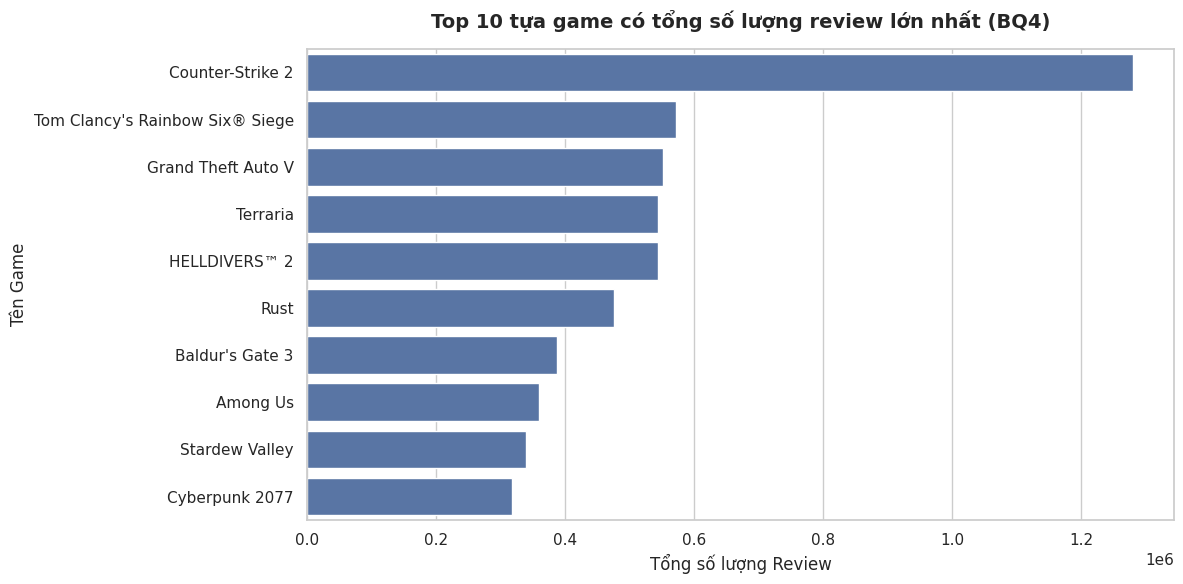

In [ ]:
# Gọi hàm lấy dữ liệu BQ4 từ file SQL
df_bq4 = load_sql_to_df('bq04_top_reviewed_games.sql')

df_top10 = df_bq4.head(10)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=df_top10, 
    x='total_reviews_calc', 
    y='name'
)
plt.title('Top 10 tựa game có tổng số lượng review lớn nhất (BQ4)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tổng số lượng Review', fontsize=12)
plt.ylabel('Tên Game', fontsize=12)
plt.tight_layout()
plt.show()

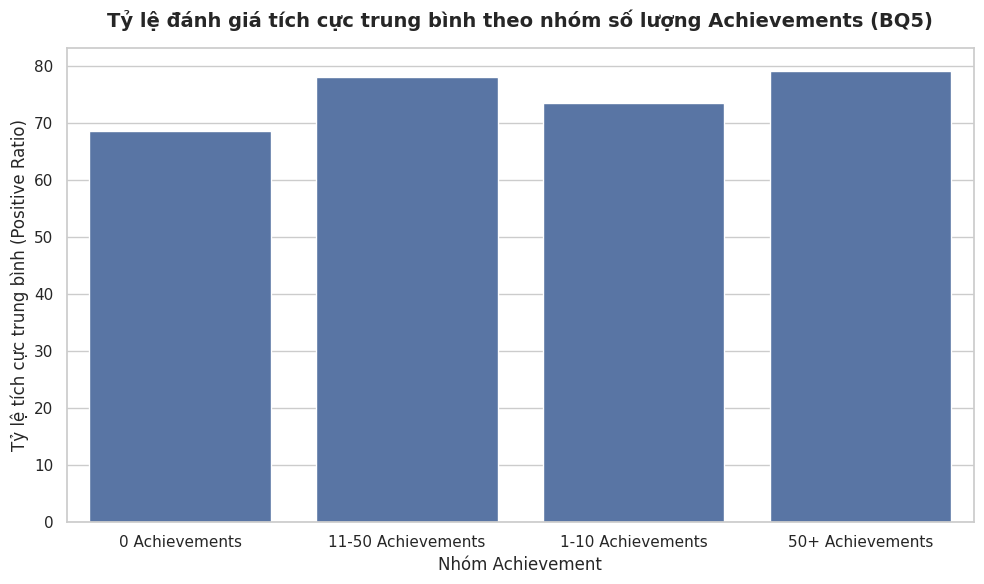

In [ ]:
# Gọi hàm lấy dữ liệu BQ5 từ file SQL
df_bq5 = load_sql_to_df('bq05_achievement_analysis.sql')

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df_bq5, 
    x='achievement_group', 
    y='avg_positive_ratio'
)
plt.title('Tỷ lệ đánh giá tích cực trung bình theo nhóm số lượng Achievements (BQ5)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nhóm Achievement', fontsize=12)
plt.ylabel('Tỷ lệ tích cực trung bình (Positive Ratio)', fontsize=12)
plt.tight_layout()
plt.show()

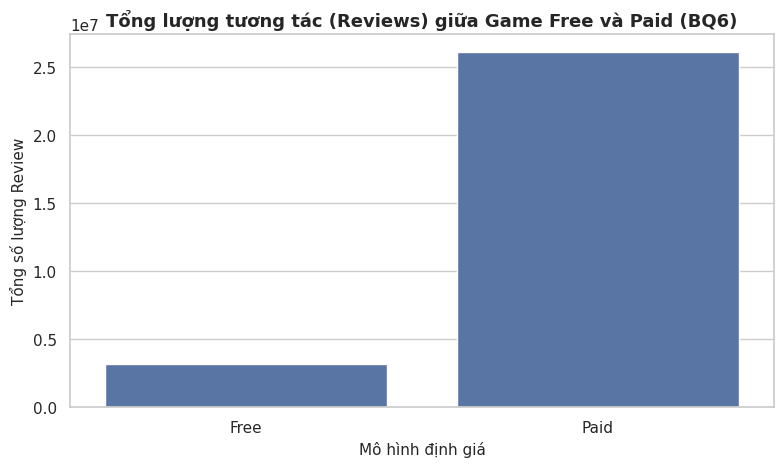

In [14]:
df_bq6 = load_sql_to_df('bq06_free_vs_paid_performance.sql')

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_bq6, 
    x='pricing_model', 
    y='total_reviews_sum'
)
plt.title('Tổng lượng tương tác (Reviews) giữa Game Free và Paid (BQ6)', fontsize=13, fontweight='bold')
plt.xlabel('Mô hình định giá', fontsize=11)
plt.ylabel('Tổng số lượng Review', fontsize=11)
plt.tight_layout()
plt.show()

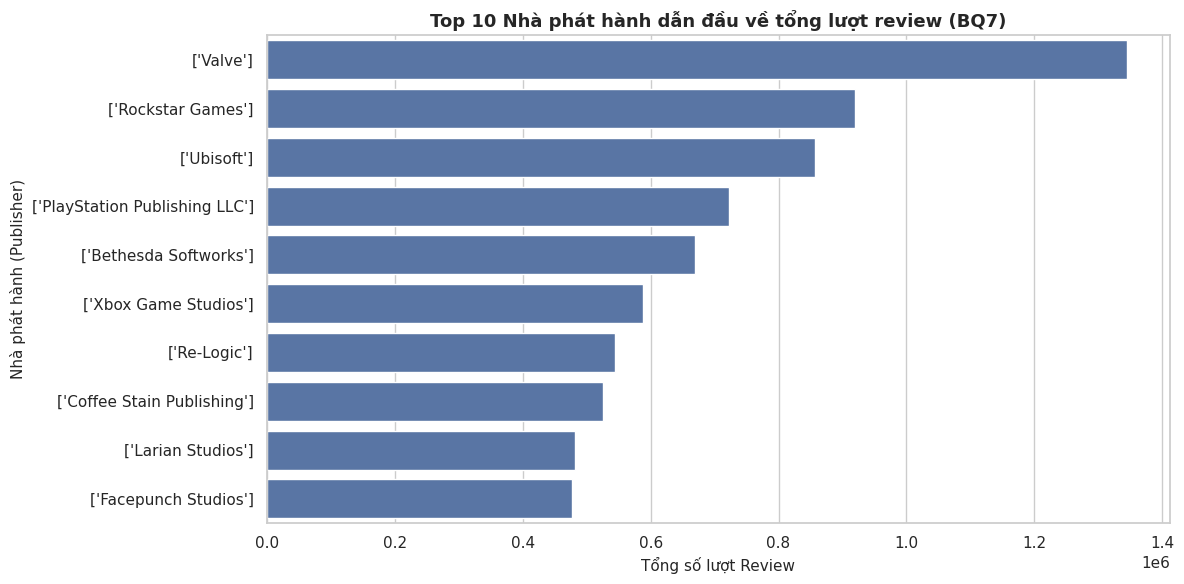

In [19]:
df_bq7 = load_sql_to_df('bq07_publisher_analysis.sql')

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_bq7.head(10), 
    x='total_reviews_sum', 
    y='publishers'
)

plt.title('Top 10 Nhà phát hành dẫn đầu về tổng lượt review (BQ7)', fontsize=13, fontweight='bold')
plt.xlabel('Tổng số lượt Review', fontsize=11)
plt.ylabel('Nhà phát hành (Publisher)', fontsize=11)
plt.tight_layout()
plt.show()

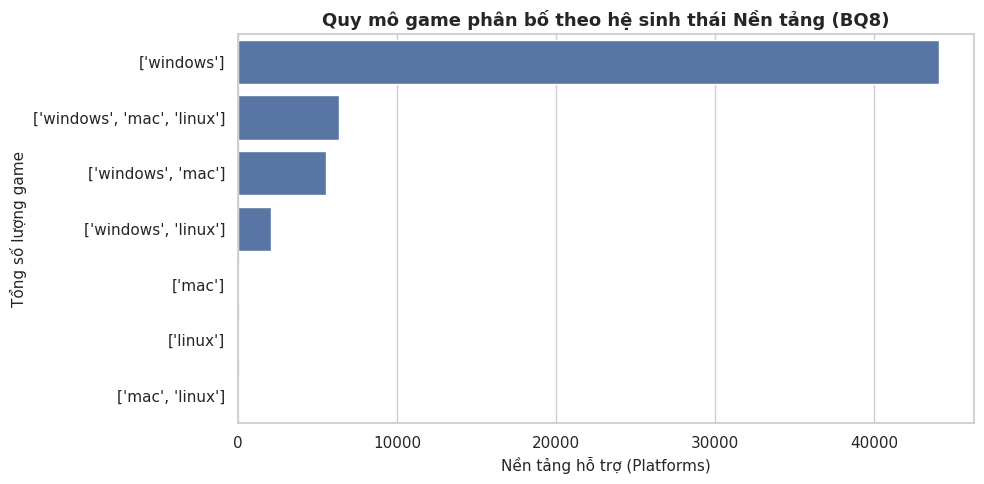

In [22]:
# BQ8: Phân bố nền tảng hỗ trợ
df_bq8 = load_sql_to_df('bq08_platform_compatibility.sql')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_bq8, 
    y='platforms', 
    x='total_games'
)

plt.title('Quy mô game phân bố theo hệ sinh thái Nền tảng (BQ8)', fontsize=13, fontweight='bold')
plt.xlabel('Nền tảng hỗ trợ (Platforms)', fontsize=11)
plt.ylabel('Tổng số lượng game', fontsize=11)
plt.tight_layout()
plt.show()

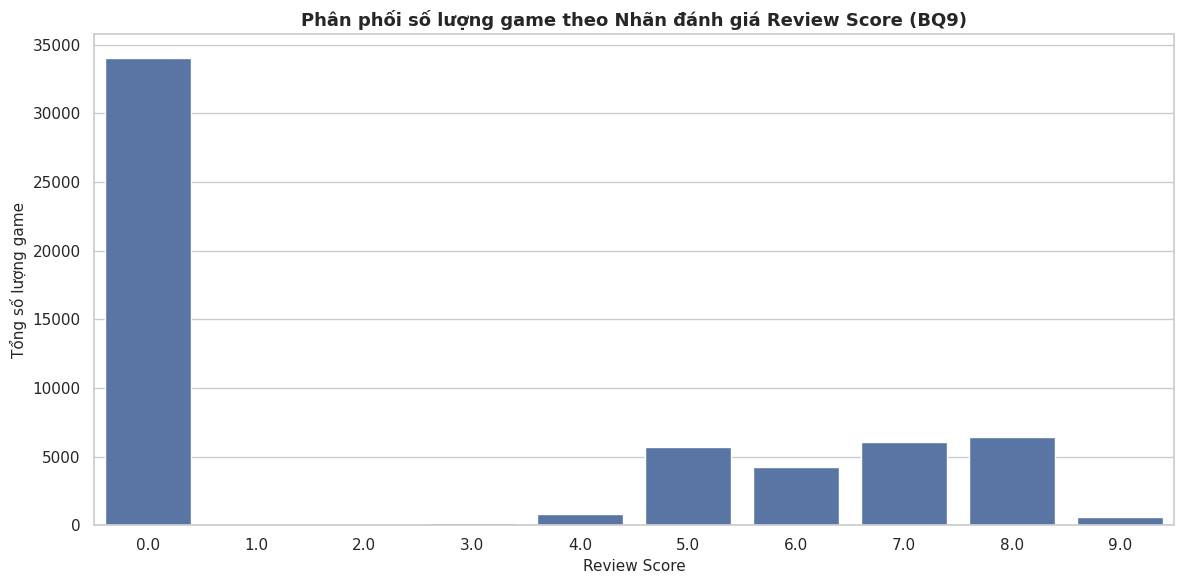

In [24]:
# BQ9: Phân phối Review Score
df_bq9 = load_sql_to_df('bq09_review_score_distribution.sql')

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_bq9, 
    x='review_score', 
    y='total_games'
)

plt.title('Phân phối số lượng game theo Nhãn đánh giá Review Score (BQ9)', fontsize=13, fontweight='bold')
plt.xlabel('Review Score', fontsize=11)
plt.ylabel('Tổng số lượng game', fontsize=11)
plt.tight_layout()
plt.show()

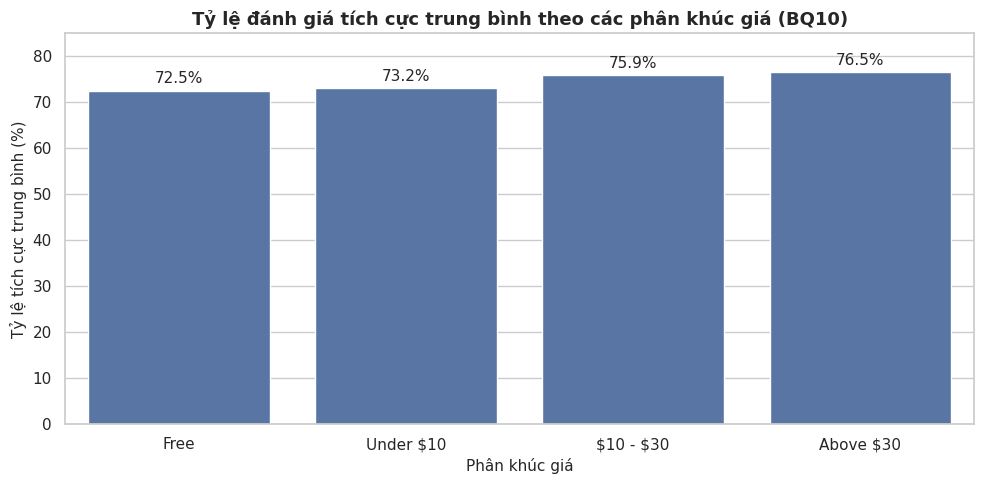

In [ ]:
# BQ10: Tương quan Phân khúc giá và Tỷ lệ tích cực
plt.rcParams['text.parse_math'] = False 

df_bq10 = load_sql_to_df('bq10_price_vs_rating_correlation.sql')

order = ['Free', 'Under $10', '$10 - $30', 'Above $30']

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_bq10,
    x='price_tier',
    y='avg_positive_ratio',
    order=order,
)

# Data labels trên đầu cột
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=11)

ax.set_ylim(0, 85)   # chừa chỗ cho nhãn
plt.title('Tỷ lệ đánh giá tích cực trung bình theo các phân khúc giá (BQ10)', fontsize=13, fontweight='bold')
plt.xlabel('Phân khúc giá', fontsize=11)
plt.ylabel('Tỷ lệ tích cực trung bình (%)', fontsize=11)
plt.tight_layout()
plt.show()

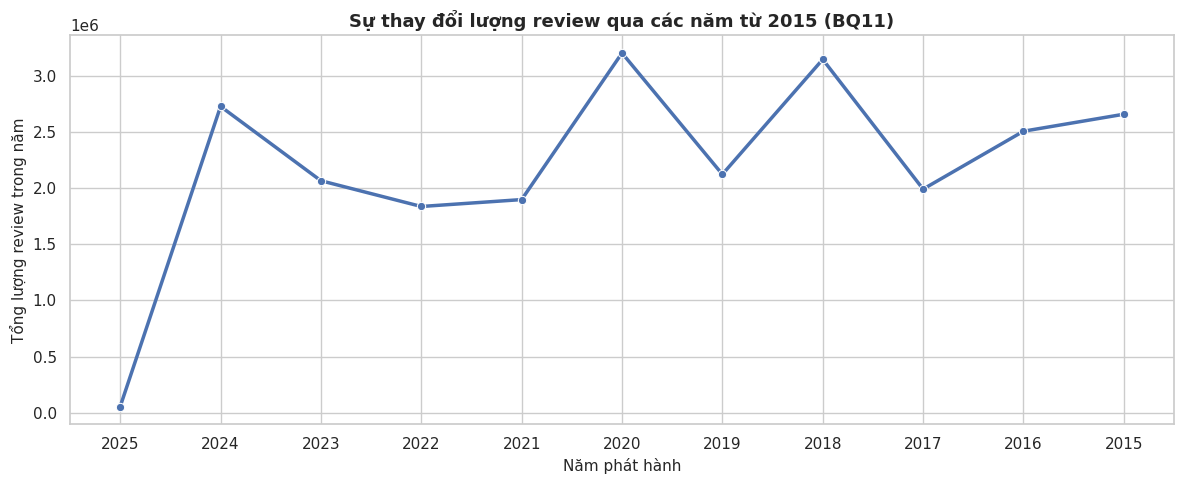

In [35]:
# BQ11: Tăng trưởng các năm gần đây (2015+)
df_bq11 = load_sql_to_df('bq11_recent_years_growth.sql')

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_bq11, 
    x='release_year', 
    y='annual_reviews', 
    marker='o', 
    color='b', 
    linewidth=2.5
)

plt.title('Sự thay đổi lượng review qua các năm từ 2015 (BQ11)', fontsize=13, fontweight='bold')
plt.xlabel('Năm phát hành', fontsize=11)
plt.ylabel('Tổng lượng review trong năm', fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

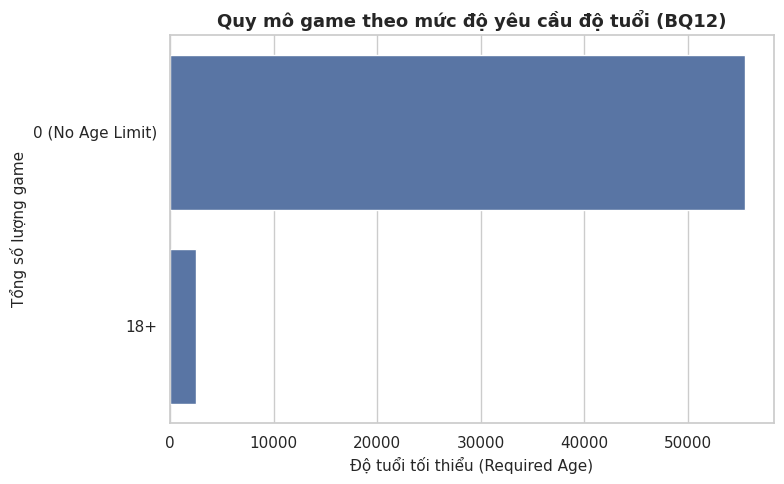

In [40]:
# BQ12: Tác động của yêu cầu độ tuổi (Required Age)
df_bq12 = load_sql_to_df('bq12_mature_content_impact.sql')

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df_bq12, 
    y='age_group', 
    x='total_games'
)

plt.title('Quy mô game theo mức độ yêu cầu độ tuổi (BQ12)', fontsize=13, fontweight='bold')
plt.xlabel('Độ tuổi tối thiểu (Required Age)', fontsize=11)
plt.ylabel('Tổng số lượng game', fontsize=11)
plt.tight_layout()
plt.show()